# Unit 5 — Menentukan Objek Data
**Kode unit:** J.62DMI00.007.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini menetapkan **unit analisis**, **definisi target**, **record** yang dipakai, dan **atribut** yang dipilih beserta alasannya. Relevansi tiap variabel diuji secara statistik pada periode eksplorasi 2010–2022. Hasilnya adalah rencana fitur (`reports/feature_plan.csv`) yang dieksekusi pada Unit 7.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

In [2]:
from scipy import stats
from matplotlib.ticker import PercentFormatter

raw = pd.read_csv(RAW, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
log = pd.read_csv(REP / 'anomalies.csv', parse_dates=['Date'])
drop_missing = set(log.loc[log.variabel.eq('SEMUA_PASAR'), 'Date'])
drop_holiday = set(log.loc[log.variabel.eq('IHSG') & log.tindakan.eq('hapus_baris'), 'Date'])
print(f'Data mentah: {len(raw):,} baris | log anomali Unit 4: {len(log):,} entri')

Data mentah: 4,277 baris | log anomali Unit 4: 339 entri


## 1. Unit analisis dan definisi target

- **Unit analisis:** satu **hari bursa BEI** $t$ (bukan hari kalender, bukan hari kerja gabungan).
- **Target:** $y_t = 1$ jika $\text{IHSG}_{t+1} > \text{IHSG}_t$ (**Naik**), selain itu $y_t = 0$ (**Turun/Tetap**).
  Karena hari libur BEI dikeluarkan, kasus "tetap" (perubahan tepat nol) praktis tidak ada.
- $t+1$ adalah **hari bursa BEI berikutnya**, bukan hari kalender berikutnya — setelah libur panjang (mis. Lebaran),
  target mencakup seluruh periode libur.

Contoh pembentukan target pada beberapa hari pertama:

In [3]:
demo = raw[~raw.Date.isin(drop_missing | drop_holiday)][['Date', 'IHSG']].head(9).copy()
demo['IHSG_hari_bursa_berikutnya'] = demo.IHSG.shift(-1)
demo['y'] = np.where(demo.IHSG.shift(-1) > demo.IHSG, 1, 0)
demo['label'] = demo.y.map({1: 'Naik', 0: 'Turun/Tetap'})
display(demo.head(8).reset_index(drop=True))

,Date,IHSG,IHSG_hari_bursa_berikutnya,y,label
0,2010-01-04,"2,575.3130","2,605.1755",1,Naik
1,2010-01-05,"2,605.1755","2,603.1956",0,Turun/Tetap
2,2010-01-06,"2,603.1956","2,586.7942",0,Turun/Tetap
3,2010-01-07,"2,586.7942","2,614.2683",1,Naik
4,2010-01-08,"2,614.2683","2,632.1016",1,Naik
5,2010-01-11,"2,632.1016","2,659.4473",1,Naik
6,2010-01-12,"2,659.4473","2,632.7695",0,Turun/Tetap
7,2010-01-13,"2,632.7695","2,645.0779",1,Naik


## 2. Seleksi record

In [4]:
n0 = len(raw)
n1 = n0 - len(drop_missing)
n2 = n1 - len(drop_holiday)
n3 = n2 - 1
selection = pd.DataFrame([
    ('Data mentah (kalender hari kerja gabungan)', n0, ''),
    ('Keluarkan baris tanpa data pasar (1 Jan 2010)', n1, f'-{n0 - n1}'),
    ('Pertahankan hanya hari bursa BEI', n2, f'-{n1 - n2}'),
    ('Keluarkan hari terakhir (target belum diketahui)', n3, '-1'),
], columns=['Langkah seleksi', 'Jumlah record', 'Perubahan'])
display(selection)

,Langkah seleksi,Jumlah record,Perubahan
0,Data mentah (kalender hari kerja gabungan),4277,
1,Keluarkan baris tanpa data pasar (1 Jan 2010),4276,-1
2,Pertahankan hanya hari bursa BEI,3976,-300
3,Keluarkan hari terakhir (target belum diketahui),3975,-1


Pengurangan record tambahan yang **sudah direncanakan**: Januari 2010 (belum ada nilai suku bunga bulan sebelumnya,
Unit 6) dan ±20 hari pertama (jendela bergulir fitur, Unit 7).

## 3. Seleksi atribut

| Variabel mentah | Keputusan | Bentuk yang dipakai | Alasan |
|---|---|---|---|
| `IHSG` | Dipakai | Return, lag return, momentum, jarak ke rata-rata bergerak, volatilitas | Sumber target; dinamika jangka pendek IHSG sendiri |
| `SP500` | Dipakai | Return sesi hari $t$ dan $t-1$ | Sesi AS berlangsung **setelah** BEI tutup → informasi baru semalam |
| `VIX` | Dipakai | Level dan perubahan harian | Sentimen risiko global (*risk-on/risk-off*) |
| `OIL` | Dipakai | Return harian | Indonesia eksportir komoditas energi; sektor energi berbobot di IHSG |
| `GOLD` | Dipakai | Return harian | Aset *safe haven*; sinyal sentimen global |
| `USDIDR` | Dipakai | Return harian (positif = rupiah melemah) | Aliran dana asing dan risiko mata uang |
| `BI_rate`, `US_rate` | Dipakai | Selisih `BI_rate − US_rate` (nilai *point-in-time*) | Diferensial kebijakan moneter → daya tarik aset rupiah |
| `CPI` | **Dikeluarkan** | – | *Look-ahead bias* (nilai tahunan ditempel sejak 1 Januari) dan hanya 17 nilai unik (berperan sebagai penanda tahun) |
| Level harga mentah | **Tidak dipakai langsung** | Diganti return/rasio | Level harga tidak stasioner; pola "IHSG > 7.000" tidak berlaku di masa depan |
| `Date` | Indeks | – | Hanya untuk urutan waktu dan pemisahan data |

## 4. Uji relevansi (periode eksplorasi 2010–2022)

Untuk setiap variabel harian dihitung peluang IHSG naik **besok** dengan syarat variabel tersebut naik vs turun **hari ini**,
lalu diuji dengan **uji chi-kuadrat independensi**. Koreksi data dari log anomali Unit 4 diterapkan sementara agar
kutipan janggal tidak mengganggu hasil (pembersihan formal ada di Unit 6).

Periode 2010–2022, 3,171 hari bursa; P(IHSG naik besok) rata-rata = 54.5%


,variabel,n,P(naik besok | X naik),P(naik besok | X turun),selisih,p_value,"signifikan (α=0,05)"
0,SP500,3092,0.6379,0.4321,0.2059,0.0000,Ya
1,VIX,3080,0.4468,0.6267,-0.1799,0.0000,Ya
2,OIL,3080,0.5871,0.4942,0.0929,0.0000,Ya
3,GOLD,3077,0.5664,0.5181,0.0483,0.0081,Ya
4,USDIDR,3072,0.5351,0.5535,-0.0184,0.3228,Tidak
5,IHSG,3170,0.5411,0.5492,-0.0081,0.6723,Tidak


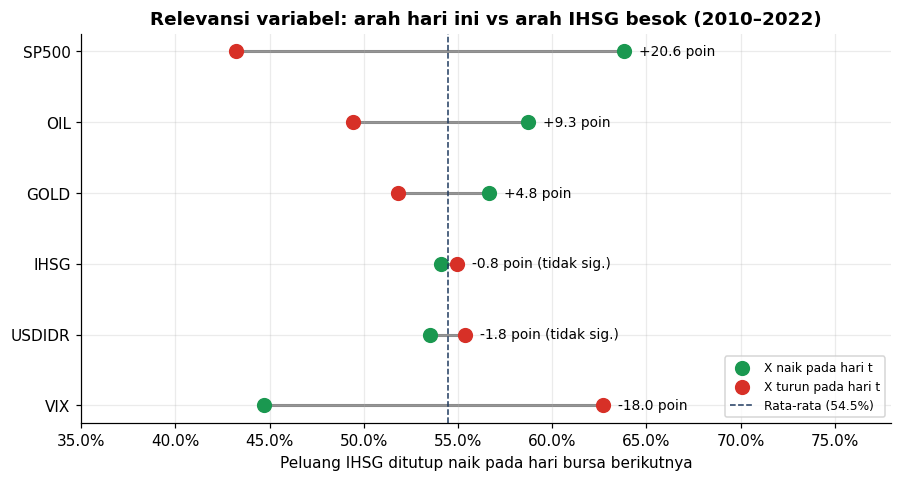

In [5]:
p = raw.copy()
for var in ['USDIDR', 'OIL']:
    p.loc[p.Date.isin(log.loc[log.variabel.eq(var), 'Date']), var] = np.nan
    p[var] = p[var].ffill()
p = p[~p.Date.isin(drop_missing | drop_holiday)]
p = p[p.Date <= EDA_END].reset_index(drop=True)

has_next = p.IHSG.shift(-1).notna()
up_next = p.IHSG.shift(-1) > p.IHSG
base_rate = up_next[has_next].mean()

rel = []
for c in ['SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR', 'IHSG']:
    x = p[c].pct_change()
    m = has_next & x.notna() & x.ne(0)
    x_up, yy = x[m] > 0, up_next[m]
    chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(x_up, yy))
    rel.append({'variabel': c, 'n': int(m.sum()),
                'p_naik': yy[x_up].mean(), 'p_turun': yy[~x_up].mean(),
                'selisih': yy[x_up].mean() - yy[~x_up].mean(), 'p_value': pval})
rel = pd.DataFrame(rel).sort_values('selisih', key=abs, ascending=False).reset_index(drop=True)
rel['signifikan (α=0,05)'] = np.where(rel.p_value < 0.05, 'Ya', 'Tidak')
print(f'Periode {p.Date.min():%Y}–{p.Date.max():%Y}, {int(has_next.sum()):,} hari bursa; P(IHSG naik besok) rata-rata = {base_rate:.1%}')
display(rel.rename(columns={'p_naik': 'P(naik besok | X naik)', 'p_turun': 'P(naik besok | X turun)'}))

relv = rel.sort_values('selisih').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9.5, 4.6))
for i, r in relv.iterrows():
    ax.plot([r.p_turun, r.p_naik], [i, i], color=C_GREY, lw=2, zorder=1)
    ax.scatter(r.p_naik, i, color=C_UP, s=80, zorder=2, label='X naik pada hari t' if i == 0 else None)
    ax.scatter(r.p_turun, i, color=C_DOWN, s=80, zorder=2, label='X turun pada hari t' if i == 0 else None)
    ax.text(max(r.p_naik, r.p_turun) + 0.008, i, f'{r.selisih * 100:+.1f} poin' + ('' if r.p_value < 0.05 else ' (tidak sig.)'),
            va='center', fontsize=9)
ax.axvline(base_rate, color=C_NAVY, ls='--', lw=1, label=f'Rata-rata ({base_rate:.1%})')
ax.set_yticks(range(len(relv))); ax.set_yticklabels(relv.variabel)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0.35, 0.78)
ax.set_xlabel('Peluang IHSG ditutup naik pada hari bursa berikutnya')
ax.set_title('Relevansi variabel: arah hari ini vs arah IHSG besok (2010–2022)')
ax.legend(loc='lower right', fontsize=8)
plt.savefig(FIG / '05_conditional_probability.png')
plt.show()

Apakah hubungan terkuat **stabil dari tahun ke tahun**, atau hanya muncul pada periode tertentu?

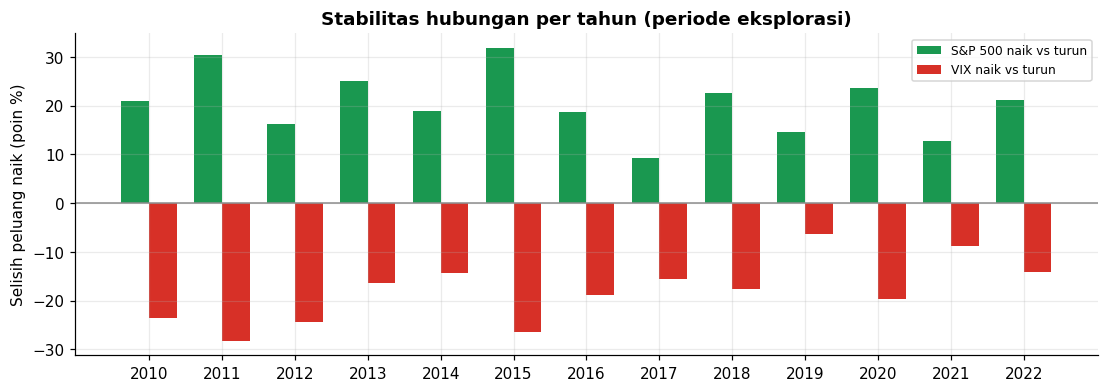

Tahun dengan arah hubungan S&P 500 konsisten positif: 13 dari 13
Tahun dengan arah hubungan VIX konsisten negatif   : 13 dari 13


In [6]:
stab = []
for year, g in p.assign(up_next=up_next, has_next=has_next).groupby(p.Date.dt.year):
    row = {'tahun': year}
    for c in ['SP500', 'VIX']:
        x = g[c].pct_change()
        m = g.has_next & x.notna() & x.ne(0)
        row[c] = g.up_next[m][x[m] > 0].mean() - g.up_next[m][x[m] < 0].mean()
    stab.append(row)
stab = pd.DataFrame(stab).set_index('tahun')

fig, ax = plt.subplots(figsize=(12, 3.8))
w = 0.38
ax.bar(stab.index - w / 2, stab.SP500 * 100, w, color=C_UP, label='S&P 500 naik vs turun')
ax.bar(stab.index + w / 2, stab.VIX * 100, w, color=C_DOWN, label='VIX naik vs turun')
ax.axhline(0, color=C_GREY, lw=1)
ax.set_xticks(stab.index)
ax.set_ylabel('Selisih peluang naik (poin %)')
ax.set_title('Stabilitas hubungan per tahun (periode eksplorasi)')
ax.legend(fontsize=8)
plt.savefig(FIG / '05_relevance_stability.png')
plt.show()
print('Tahun dengan arah hubungan S&P 500 konsisten positif:', int((stab.SP500 > 0).sum()), 'dari', len(stab))
print('Tahun dengan arah hubungan VIX konsisten negatif   :', int((stab.VIX < 0).sum()), 'dari', len(stab))

## 5. Rencana fitur dan definisi objek data

Berdasarkan seleksi atribut dan uji relevansi, ditetapkan **16 fitur** yang dibangun pada Unit 7.
Semua fitur hanya memakai informasi hingga hari $t$.

In [7]:
feature_plan = pd.DataFrame([
    ('ihsg_ret', 'IHSG', 'Return IHSG hari t (%)', 'Momentum/pembalikan sangat pendek'),
    ('ihsg_ret_lag1', 'IHSG', 'Return IHSG hari t-1 (%)', 'Memori pasar'),
    ('ihsg_ret_lag2', 'IHSG', 'Return IHSG hari t-2 (%)', 'Memori pasar'),
    ('ihsg_ret_lag3', 'IHSG', 'Return IHSG hari t-3 (%)', 'Memori pasar'),
    ('ihsg_mom_5d', 'IHSG', 'Return IHSG 5 hari bursa terakhir (%)', 'Momentum mingguan'),
    ('ihsg_dist_ma5', 'IHSG', 'Jarak penutupan ke rata-rata 5 hari (%)', 'Kondisi jenuh beli/jual jangka pendek'),
    ('ihsg_dist_ma20', 'IHSG', 'Jarak penutupan ke rata-rata 20 hari (%)', 'Posisi terhadap tren bulanan'),
    ('ihsg_vol_10d', 'IHSG', 'Simpangan baku return 10 hari (%)', 'Rezim volatilitas'),
    ('sp500_ret', 'SP500', 'Return S&P 500 sesi hari t (%)', 'Limpahan sesi AS semalam'),
    ('sp500_ret_lag1', 'SP500', 'Return S&P 500 sesi hari t-1 (%)', 'Limpahan tertunda'),
    ('vix_level', 'VIX', 'Level VIX hari t', 'Tingkat kecemasan pasar global'),
    ('vix_chg', 'VIX', 'Perubahan VIX hari t (%)', 'Perubahan sentimen risiko'),
    ('oil_ret', 'OIL', 'Return minyak hari t (%)', 'Sentimen komoditas energi'),
    ('gold_ret', 'GOLD', 'Return emas hari t (%)', 'Permintaan safe haven'),
    ('usdidr_ret', 'USDIDR', 'Return USD/IDR hari t (%), positif = rupiah melemah', 'Aliran dana asing'),
    ('rate_spread', 'BI_rate, US_rate', 'BI_rate − US_rate, nilai akhir bulan sebelumnya (poin %)', 'Diferensial kebijakan moneter'),
], columns=['fitur', 'sumber', 'definisi', 'alasan'])
feature_plan.to_csv(REP / 'feature_plan.csv', index=False)
display(feature_plan)

object_definition = {
    'unit_analisis': 'Satu hari bursa BEI (t)',
    'target': 'y=1 jika IHSG(t+1) > IHSG(t), t+1 = hari bursa BEI berikutnya',
    'record': {'mentah': n0, 'setelah_seleksi': n3},
    'atribut_dipakai': ['IHSG', 'SP500', 'VIX', 'OIL', 'GOLD', 'USDIDR', 'BI_rate', 'US_rate'],
    'atribut_dikeluarkan': {'CPI': 'look-ahead bias dan hanya 17 nilai unik (penanda tahun)'},
    'jumlah_fitur_rencana': len(feature_plan),
    'relevansi_eda': rel.set_index('variabel')[['p_naik', 'p_turun', 'selisih', 'p_value']].round(4).to_dict('index'),
    'proporsi_naik_eda': round(float(base_rate), 4),
}
with open(REP / 'object_definition.json', 'w', encoding='utf-8') as f:
    json.dump(object_definition, f, ensure_ascii=False, indent=2)
print('Tersimpan ->', REP / 'feature_plan.csv', 'dan', REP / 'object_definition.json')

,fitur,sumber,definisi,alasan
0,ihsg_ret,IHSG,Return IHSG hari t (%),Momentum/pembalikan sangat pendek
1,ihsg_ret_lag1,IHSG,Return IHSG hari t-1 (%),Memori pasar
2,ihsg_ret_lag2,IHSG,Return IHSG hari t-2 (%),Memori pasar
3,ihsg_ret_lag3,IHSG,Return IHSG hari t-3 (%),Memori pasar
4,ihsg_mom_5d,IHSG,Return IHSG 5 hari bursa terakhir (%),Momentum mingguan
5,ihsg_dist_ma5,IHSG,Jarak penutupan ke rata-rata 5 hari (%),Kondisi jenuh beli/jual jangka pendek
6,ihsg_dist_ma20,IHSG,Jarak penutupan ke rata-rata 20 hari (%),Posisi terhadap tren bulanan
7,ihsg_vol_10d,IHSG,Simpangan baku return 10 hari (%),Rezim volatilitas
8,sp500_ret,SP500,Return S&P 500 sesi hari t (%),Limpahan sesi AS semalam
9,sp500_ret_lag1,SP500,Return S&P 500 sesi hari t-1 (%),Limpahan tertunda


Tersimpan -> ../reports/feature_plan.csv dan ../reports/object_definition.json


In [8]:
sig = rel[rel.p_value < 0.05].variabel.tolist()
nonsig = rel[rel.p_value >= 0.05].variabel.tolist()
display(Markdown(f'''
### Ringkasan Unit 5

- **Objek data:** {n3:,} hari bursa BEI dengan target arah IHSG hari bursa berikutnya; proporsi hari "naik" pada periode eksplorasi {base_rate:.1%}.
- **Variabel yang terbukti relevan** (chi-kuadrat, α = 0,05): {", ".join(sig) if sig else "-"}.
  Variabel tidak signifikan secara univariat: {", ".join(nonsig) if nonsig else "-"} — tetap dipertahankan karena dapat berguna
  dalam kombinasi (interaksi) dan biayanya rendah; kontribusinya diuji ulang dengan *permutation importance* di Unit 10.
- **Hubungan terkuat:** {rel.variabel.iloc[0]} — peluang IHSG naik besok {rel.p_naik.iloc[0]:.1%} bila {rel.variabel.iloc[0]} naik,
  vs {rel.p_turun.iloc[0]:.1%} bila turun.
- **CPI dikeluarkan** karena *look-ahead bias*. 16 fitur direncanakan di `reports/feature_plan.csv`.
'''))


### Ringkasan Unit 5

- **Objek data:** 3,975 hari bursa BEI dengan target arah IHSG hari bursa berikutnya; proporsi hari "naik" pada periode eksplorasi 54.5%.
- **Variabel yang terbukti relevan** (chi-kuadrat, α = 0,05): SP500, VIX, OIL, GOLD.
  Variabel tidak signifikan secara univariat: USDIDR, IHSG — tetap dipertahankan karena dapat berguna
  dalam kombinasi (interaksi) dan biayanya rendah; kontribusinya diuji ulang dengan *permutation importance* di Unit 10.
- **Hubungan terkuat:** SP500 — peluang IHSG naik besok 63.8% bila SP500 naik,
  vs 43.2% bila turun.
- **CPI dikeluarkan** karena *look-ahead bias*. 16 fitur direncanakan di `reports/feature_plan.csv`.
